In [2]:
import sys
print(sys.executable)

C:\Users\saras\Desktop\paypal-hackathon\payflow-intelligence\backend\venv\Scripts\python.exe


In [4]:
def create_treasury_plan(req: PlanRequest):
    thread_id = f"run-{uuid.uuid4().hex[:8]}"
    config = {"configurable": {"thread_id": thread_id}}

    initial_state = {
        "merchant_query": req.merchant_query,
        "audit_log": [],
    }

    treasury_graph.invoke(initial_state, config=config)
    snapshot = treasury_graph.get_state(config)
    return {"thread_id": thread_id, "state": snapshot.values}

def execute_approved_plan(req: ExecuteRequest):
    config = {"configurable": {"thread_id": req.thread_id}}
    snapshot = treasury_graph.get_state(config)
    if not snapshot.values:
        raise HTTPException(status_code=404, detail="Run thread_id not found")

    treasury_graph.invoke(
        Command(resume={"approved_lever_ids": req.approved_lever_ids}),
        config=config,
    )
    final_snapshot = treasury_graph.get_state(config)
    return {"thread_id": req.thread_id, "state": final_snapshot.values}


def get_run_state(thread_id: str):
    config = {"configurable": {"thread_id": thread_id}}
    snapshot = treasury_graph.get_state(config)
    if not snapshot.values:
        raise HTTPException(status_code=404, detail="Run thread_id not found")
    return {"thread_id": thread_id, "state": snapshot.values}


In [5]:
from typing import Any, Dict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
from langgraph.types import interrupt
from app.graph.state import TreasuryState
from app.graph.nodes import (
    diagnose_cash_gap,
    analyze_disputes,
    analyze_invoices,
    synthesize_plan,
    execute_plan,
    verify_and_audit,
)


def merchant_approval(state: TreasuryState) -> Dict[str, Any]:
    """Pauses execution using LangGraph interrupt() until the merchant approves selected actions."""
    decision = interrupt(
        {
            "thread_status": "WAITING_FOR_MERCHANT_APPROVAL",
            "initial_gap_usd": state["initial_gap_usd"],
            "immediate_friday_cash_usd": state["immediate_friday_cash_usd"],
            "ranked_options_count": len(state.get("ranked_options", [])),
        }
    )
    approved_ids = decision.get("approved_lever_ids", [])
    return {
        "approval_status": "APPROVED" if approved_ids else "REJECTED",
        "approved_lever_ids": approved_ids,
    }


def build_treasury_graph():
    builder = StateGraph(TreasuryState)

    builder.add_node("diagnose_cash_gap", diagnose_cash_gap)
    builder.add_node("analyze_disputes", analyze_disputes)
    builder.add_node("analyze_invoices", analyze_invoices)
    builder.add_node("synthesize_plan", synthesize_plan)
    builder.add_node("merchant_approval", merchant_approval)
    builder.add_node("execute_plan", execute_plan)
    builder.add_node("verify_and_audit", verify_and_audit)

    # Parallel fan-out & fan-in matching the architecture diagram
    builder.add_edge(START, "diagnose_cash_gap")
    builder.add_edge("diagnose_cash_gap", "analyze_disputes")
    builder.add_edge("diagnose_cash_gap", "analyze_invoices")
    builder.add_edge("analyze_disputes", "synthesize_plan")
    builder.add_edge("analyze_invoices", "synthesize_plan")
    builder.add_edge("synthesize_plan", "merchant_approval")
    builder.add_edge("merchant_approval", "execute_plan")
    builder.add_edge("execute_plan", "verify_and_audit")
    builder.add_edge("verify_and_audit", END)

    # Allow LangGraph to restore our own Pydantic state classes from checkpoints
    # (LangGraph 1.2+ warns on unregistered types and will block them in future).
    serde = JsonPlusSerializer(
        allowed_msgpack_modules=[
            ("app.graph.state", "SupplierObligation"),
            ("app.graph.state", "DisputeEvidence"),
            ("app.graph.state", "OverdueInvoice"),
            ("app.graph.state", "LiquidityLever"),
            ("app.graph.state", "AuditLogEntry"),
        ]
    )
    checkpointer = MemorySaver(serde=serde)
    return builder.compile(checkpointer=checkpointer)


treasury_graph = build_treasury_graph()

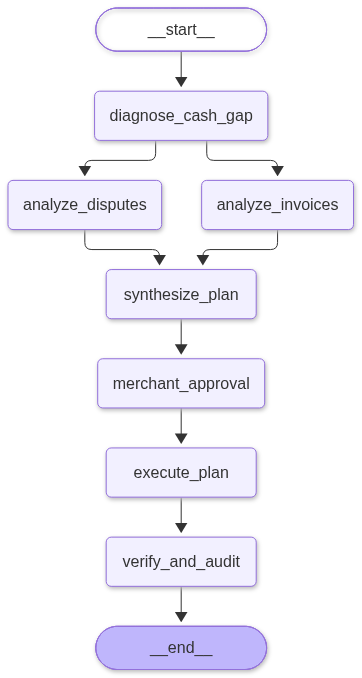

In [6]:
from IPython.display import Image, display
Image(treasury_graph.get_graph().draw_mermaid_png())

In [7]:
import os
import time
import uuid
import httpx
from typing import Any, Dict, List, Optional
from dotenv import load_dotenv

load_dotenv()


class PayPalSandboxClient:
    def __init__(self) -> None:
        self.client_id = os.getenv("PAYPAL_CLIENT_ID", "")
        self.client_secret = os.getenv("PAYPAL_CLIENT_SECRET", "")
        self.base_url = "https://api-m.sandbox.paypal.com"
        self._access_token: Optional[str] = None
        self._token_expiry: float = 0.0

        # Optional PayPal Agent Toolkit initialization for hackathon compliance
        self.toolkit = None
        try:
            from paypal_agent_toolkit.langchain.toolkit import PayPalToolkit
            if self.client_id and self.client_secret:
                self.toolkit = PayPalToolkit(
                    client_id=self.client_id,
                    secret=self.client_secret,
                    environment="sandbox",
                )
        except Exception:
            self.toolkit = None

    def _get_token(self) -> str:
        if self._access_token and time.time() < self._token_expiry:
            return self._access_token

        if not self.client_id or not self.client_secret:
            raise ValueError("Missing PAYPAL_CLIENT_ID or PAYPAL_CLIENT_SECRET in .env")

        with httpx.Client(timeout=20.0) as client:
            resp = client.post(
                f"{self.base_url}/v1/oauth2/token",
                auth=(self.client_id, self.client_secret),
                data={"grant_type": "client_credentials"},
                headers={"Accept": "application/json"},
            )
            resp.raise_for_status()
            data = resp.json()
            self._access_token = data["access_token"]
            self._token_expiry = time.time() + int(data.get("expires_in", 3200)) - 60
            return self._access_token

    def _headers(self) -> Dict[str, str]:
        return {
            "Authorization": f"Bearer {self._get_token()}",
            "Content-Type": "application/json",
            "Accept": "application/json",
        }

    # --- READ-ONLY OPERATIONS (Used above Merchant Approval gate) ---

    def get_available_balance_usd(self) -> float:
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.get(
                    f"{self.base_url}/v1/reporting/balances",
                    params={"currency_code": "USD"},
                    headers=self._headers(),
                )
                if resp.status_code == 200:
                    balances = resp.json().get("balances", [])
                    for b in balances:
                        if b.get("currency") == "USD":
                            val = b.get("available_balance", {}).get("value")
                            if val is not None:
                                return float(val)
        except Exception:
            pass
        # Baseline merchant cash before unlocking trapped working capital
        return 620.00

    def list_open_disputes(self) -> List[Dict[str, Any]]:
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.get(
                    f"{self.base_url}/v1/customer/disputes",
                    headers=self._headers(),
                )
                if resp.status_code == 200:
                    items = resp.json().get("items", [])
                    if items:
                        detailed = []
                        for item in items[:3]:
                            d_id = item.get("dispute_id")
                            detail_resp = client.get(
                                f"{self.base_url}/v1/customer/disputes/{d_id}",
                                headers=self._headers(),
                            )
                            detailed.append(
                                detail_resp.json() if detail_resp.status_code == 200 else item
                            )
                        return detailed
        except Exception:
            pass

        # Fallback only if Sandbox disputes haven't indexed yet
        return [
            {
                "dispute_id": "PP-D-90418",
                "reason": "MERCHANDISE_OR_SERVICE_NOT_RECEIVED",
                "status": "WAITING_FOR_SELLER_RESPONSE",
                "dispute_amount": {"currency_code": "USD", "value": "650.00"},
                "disputed_transactions": [{"seller_transaction_id": "CAP-88210"}],
            },
            {
                "dispute_id": "PP-D-90422",
                "reason": "MERCHANDISE_OR_SERVICE_NOT_AS_DESCRIBED",
                "status": "WAITING_FOR_SELLER_RESPONSE",
                "dispute_amount": {"currency_code": "USD", "value": "400.00"},
                "disputed_transactions": [{"seller_transaction_id": "CAP-88255"}],
            },
            {
                "dispute_id": "PP-D-90429",
                "reason": "MERCHANDISE_OR_SERVICE_NOT_RECEIVED",
                "status": "WAITING_FOR_SELLER_RESPONSE",
                "dispute_amount": {"currency_code": "USD", "value": "180.00"},
                "disputed_transactions": [{"seller_transaction_id": "CAP-88301"}],
            },
        ]

    def list_overdue_invoices(self) -> List[Dict[str, Any]]:
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.get(
                    f"{self.base_url}/v2/invoicing/invoices",
                    params={"page_size": 10, "total_required": "true"},
                    headers=self._headers(),
                )
                if resp.status_code == 200:
                    items = resp.json().get("items", [])
                    unpaid = [
                        inv for inv in items
                        if inv.get("status") in ("SENT", "UNPAID", "PARTIALLY_PAID", "PAYMENT_PENDING")
                    ]
                    if unpaid:
                        return unpaid[:4]
        except Exception:
            pass

        return [
            {
                "id": "INV2-X89A-4410-9921-1001",
                "detail": {"invoice_number": "INV-2026-104"},
                "primary_recipients": [
                    {
                        "billing_info": {
                            "name": {"full_name": "Artisan Cafe Group"},
                            "email_address": "ap@artisancafe.example.com",
                        }
                    }
                ],
                "amount": {"currency_code": "USD", "value": "520.00"},
                "days_overdue": 11,
                "historical_reliability": 0.88,
            },
            {
                "id": "INV2-X89A-4410-9921-1002",
                "detail": {"invoice_number": "INV-2026-108"},
                "primary_recipients": [
                    {
                        "billing_info": {
                            "name": {"full_name": "Metro Co-Work Pantry"},
                            "email_address": "finance@metrocowork.example.com",
                        }
                    }
                ],
                "amount": {"currency_code": "USD", "value": "340.00"},
                "days_overdue": 6,
                "historical_reliability": 0.92,
            },
            {
                "id": "INV2-X89A-4410-9921-1003",
                "detail": {"invoice_number": "INV-2026-099"},
                "primary_recipients": [
                    {
                        "billing_info": {
                            "name": {"full_name": "Harbor Bistro LLC"},
                            "email_address": "accounts@harborbistro.example.com",
                        }
                    }
                ],
                "amount": {"currency_code": "USD", "value": "450.00"},
                "days_overdue": 24,
                "historical_reliability": 0.55,
            },
        ]

    # --- WRITE OPERATIONS (Strictly gated behind Merchant Approval) ---

    def add_shipment_tracking(
        self, capture_id: str, tracking_number: str, carrier: str = "DHL"
    ) -> Dict[str, Any]:
        payload = {
            "trackers": [
                {
                    "transaction_id": capture_id,
                    "tracking_number": tracking_number,
                    "status": "DELIVERED",
                    "carrier": carrier,
                }
            ]
        }
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.post(
                    f"{self.base_url}/v1/shipping/trackers-batch",
                    json=payload,
                    headers=self._headers(),
                )
                if resp.status_code in (200, 201):
                    return {"status": "TRACKING_ADDED", "capture_id": capture_id, "live": True}
        except Exception:
            pass
        return {"status": "TRACKING_RECORDED_SANDBOX", "capture_id": capture_id, "live": False}

    def provide_dispute_evidence(
        self,
        dispute_id: str,
        carrier_name: str,
        tracking_number: str,
        notes: str,
    ) -> Dict[str, Any]:
        """Calls POST /v1/customer/disputes/{id}/provide-evidence directly."""
        payload = {
            "evidences": [
                {
                    "evidence_type": "PROOF_OF_FULFILLMENT",
                    "evidence_info": {
                        "tracking_info": [
                            {
                                "carrier_name": carrier_name,
                                "tracking_number": tracking_number,
                            }
                        ]
                    },
                    "notes": notes[:2000],
                }
            ]
        }
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.post(
                    f"{self.base_url}/v1/customer/disputes/{dispute_id}/provide-evidence",
                    json=payload,
                    headers=self._headers(),
                )
                if resp.status_code in (200, 202, 204):
                    return {"dispute_id": dispute_id, "status": "UNDER_REVIEW", "live": True}
        except Exception:
            pass
        return {"dispute_id": dispute_id, "status": "EVIDENCE_SUBMITTED", "live": False}

    def make_dispute_offer(
        self, dispute_id: str, offer_amount_usd: float, note: str
    ) -> Dict[str, Any]:
        """Calls POST /v1/customer/disputes/{id}/make-offer to settle partially and unfreeze balance."""
        payload = {
            "note": note[:2000],
            "offer_amount": {
                "currency_code": "USD",
                "value": f"{offer_amount_usd:.2f}",
            },
            "offer_type": "REFUND",
        }
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.post(
                    f"{self.base_url}/v1/customer/disputes/{dispute_id}/make-offer",
                    json=payload,
                    headers=self._headers(),
                )
                if resp.status_code in (200, 202, 204):
                    return {"dispute_id": dispute_id, "status": "OFFER_SENT", "live": True}
        except Exception:
            pass
        return {"dispute_id": dispute_id, "status": "PARTIAL_OFFER_RECORDED", "live": False}

    def send_invoice_reminder(
        self, invoice_id: str, subject: str, note: str
    ) -> Dict[str, Any]:
        payload = {
            "subject": subject,
            "note": note,
            "send_to_invoicer": True,
            "send_to_recipient": True,
        }
        try:
            with httpx.Client(timeout=15.0) as client:
                resp = client.post(
                    f"{self.base_url}/v2/invoicing/invoices/{invoice_id}/remind",
                    json=payload,
                    headers=self._headers(),
                )
                if resp.status_code in (200, 202, 204):
                    return {"invoice_id": invoice_id, "status": "REMINDER_SENT", "live": True}
        except Exception:
            pass
        return {"invoice_id": invoice_id, "status": "REMINDER_DISPATCHED", "live": False}

    def create_supplier_payout(
        self, recipient_email: str, amount_usd: float, po_reference: str
    ) -> Dict[str, Any]:
        """Calls POST /v1/payments/payouts to pay the wholesale supplier from merchant balance."""
        sender_batch_id = f"PAYFLOW-{po_reference}-{uuid.uuid4().hex[:6].upper()}"
        payload = {
            "sender_batch_header": {
                "sender_batch_id": sender_batch_id,
                "email_subject": f"Settlement for Purchase Order {po_reference}",
                "email_message": f"Automated working-capital payout for {po_reference}.",
            },
            "items": [
                {
                    "recipient_type": "EMAIL",
                    "amount": {"value": f"{amount_usd:.2f}", "currency": "USD"},
                    "note": f"Supplier settlement for {po_reference}",
                    "sender_item_id": po_reference,
                    "receiver": recipient_email,
                }
            ],
        }
        try:
            with httpx.Client(timeout=20.0) as client:
                resp = client.post(
                    f"{self.base_url}/v1/payments/payouts",
                    json=payload,
                    headers=self._headers(),
                )
                if resp.status_code in (200, 201):
                    data = resp.json()
                    batch_id = data.get("batch_header", {}).get(
                        "payout_batch_id", sender_batch_id
                    )
                    batch_status = data.get("batch_header", {}).get(
                        "batch_status", "PENDING"
                    )
                    return {
                        "payout_batch_id": batch_id,
                        "status": batch_status,
                        "live": True,
                    }
        except Exception:
            pass
        return {
            "payout_batch_id": sender_batch_id,
            "status": "PENDING_SANDBOX_SETTLEMENT",
            "live": False,
        }

    def verify_dispute_status(self, dispute_id: str) -> str:
        try:
            with httpx.Client(timeout=10.0) as client:
                resp = client.get(
                    f"{self.base_url}/v1/customer/disputes/{dispute_id}",
                    headers=self._headers(),
                )
                if resp.status_code == 200:
                    return resp.json().get("status", "UNDER_REVIEW")
        except Exception:
            pass
        return "UNDER_REVIEW"

    def verify_payout_status(self, payout_batch_id: str) -> str:
        try:
            with httpx.Client(timeout=10.0) as client:
                resp = client.get(
                    f"{self.base_url}/v1/payments/payouts/{payout_batch_id}",
                    headers=self._headers(),
                )
                if resp.status_code == 200:
                    return (
                        resp.json()
                        .get("batch_header", {})
                        .get("batch_status", "SUCCESS")
                    )
        except Exception:
            pass
        return "PROCESSING"